# 模块 5 节点壳（`/visual_tracker`）—— 消息互转

演示 `scripts/visual_tracker_node.py` 中**不依赖 ROS master 的纯函数**：

- `detections_from_msg(msg)` —— `uav_tracking/Detections` → `list[DetectedTarget]`
- `visual_tracks_to_msg(tracks)` —— `list[VisualTrack]` → `uav_tracking/VisualTrackArray`

> **运行前提**：已 `source /opt/ros/noetic/setup.bash` 与
> `source catkin_ws/devel/setup.bash`。

## 0. 环境准备

In [1]:
import os, sys

REPO = os.path.abspath(os.path.join(os.getcwd(), ".."))   # ai4/
SCRIPTS = os.path.join(REPO, "catkin_ws", "src", "uav_tracking", "scripts")
LIB = os.path.join(REPO, "catkin_ws", "src", "uav_tracking", "lib")
for p in (os.path.join(REPO, "code"), SCRIPTS, LIB):
    if p not in sys.path:
        sys.path.insert(0, p)
print("REPO =", REPO)

try:
    import rospy
    print("rospy OK")
except ImportError as exc:
    print("[阻塞] 未能 import rospy，请先 source ROS 环境：", exc)

REPO = /home/demo/桌面/ai4
rospy OK


In [2]:
# ---- ① 依赖注入：numpy 必须取自隔离目录 m4_deps（ultralytics 要求 >=1.18.5，系统只有 1.17.4）----
import os as _os, sys as _sys, glob as _glob
_HERE = _os.path.abspath(_os.getcwd())
ROOT = _HERE if _os.path.isdir(_os.path.join(_HERE, "catkin_ws")) else _os.path.dirname(_HERE)

DEPS = _os.path.join(ROOT, "catkin_ws", "src", "uav_tracking", "lib", "m4_deps")
if _os.path.isdir(DEPS):
    _sys.path.insert(0, DEPS)

import numpy as _np
print("ROOT     =", ROOT)
print("m4_deps  =", DEPS, "(存在)" if _os.path.isdir(DEPS) else "(不存在，视觉推理将跳过)")
print("numpy    =", _np.__version__, "(1.21.x = 隔离生效 / 1.17.4 = 隔离失效)")

# 取到 numpy 后，把 m4_deps 挪到 sys.path 末尾：torch/ultralytics 仍能导入，
# 但不会再遮住系统的 matplotlib —— m4_deps 里的 matplotlib 是 pip --target 装残的
# （import matplotlib.pyplot 会报 cannot import name 'rcParams'），实测不可用。
if DEPS in _sys.path:
    _sys.path.remove(DEPS)
    _sys.path.append(DEPS)

# ---- ② 绘图环境（代码书写原则 §4/§5：统一 %matplotlib inline + 中文字体）----
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"] = ["Noto Sans CJK JP", "WenQuanYi Zen Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib =", matplotlib.__version__, "(系统)")


def _find_real_image():
    for pat in ("test/M4_*/*/assets/*.jpg", "test/M4_*/*/assets/*.png",
                "test/M4_*/证据/*.png", "data/**/*.jpg", "assets/*.jpg"):
        hits = sorted(h for h in _glob.glob(_os.path.join(ROOT, pat), recursive=True)
                      if "ipynb_checkpoints" not in h)
        if hits:
            return hits[0]
    return ""


REAL_IMAGE = _find_real_image()
# 权重默认是相对路径 "yolov8n.pt"，notebook 工作目录是 code/，必须显式指向仓库根
MODEL_PATH = (_os.path.join(ROOT, "yolov8n.pt")
              if _os.path.isfile(_os.path.join(ROOT, "yolov8n.pt")) else "yolov8n.pt")
print("真实素材  =", REAL_IMAGE or "(未找到，退化为合成图)")
print("模型权重  =", MODEL_PATH)
%matplotlib inline


ROOT     = /home/demo/桌面/ai4
m4_deps  = /home/demo/桌面/ai4/catkin_ws/src/uav_tracking/lib/m4_deps (存在)
numpy    = 1.17.4 (1.21.x = 隔离生效 / 1.17.4 = 隔离失效)


matplotlib = 3.1.2 (系统)
真实素材  = /home/demo/桌面/ai4/test/M4_现场验证/实时演示/assets/bus.jpg
模型权重  = /home/demo/桌面/ai4/yolov8n.pt


## 1. `detections_from_msg` —— 消息 → 纯数据

注意：`uav_tracking.msg.VisualTrack` 与 `datatypes.VisualTrack` **同名但不同物**
（前者是 ROS 消息、后者是纯数据结构），转换函数负责二者互转。
这也是 `state_machine_node.py` 注释里说的"起别名模块避免冲突"。

In [3]:
try:
    import visual_tracker_node as vtn
    from datatypes import DetectedTarget as DetectedTargetData
    from uav_tracking.msg import DetectedTarget as DetectedTargetMsg
    from uav_tracking.msg import Detections

    # --- 空消息 ---
    print("空消息 ->", vtn.detections_from_msg(Detections()))

    # --- 有目标 ---
    msg = Detections()
    t = DetectedTargetMsg(); t.class_id = 2; t.confidence = 0.77; t.bbox = [10.0, 20.0, 30.0, 40.0]
    msg.targets.append(t)
    out = vtn.detections_from_msg(msg)
    d = out[0]
    print("转换结果 -> 类型:", type(d).__name__, "（纯逻辑层，非 ROS 消息）")
    print("            class_id=%d confidence=%.2f bbox=%s" % (d.class_id, d.confidence, d.bbox))
    print("            isinstance(DetectedTarget(纯数据)) =", isinstance(d, DetectedTargetData))
except ImportError as exc:
    print("[跳过] 需先 source ROS 并 catkin_make：", exc)

空消息 -> []
转换结果 -> 类型: DetectedTarget （纯逻辑层，非 ROS 消息）
            class_id=2 confidence=0.77 bbox=(10.0, 20.0, 30.0, 40.0)
            isinstance(DetectedTarget(纯数据)) = True


## 2. `visual_tracks_to_msg` —— 含「空也发」

**关键契约**：无航迹时必须产出**合法**的空 `VisualTrackArray`（`tracks` 为空数组）。

In [4]:
try:
    from datatypes import VisualTrack as VisualTrackData

    empty = vtn.visual_tracks_to_msg([])
    print("空列表 ->", type(empty).__name__, " tracks =", len(empty.tracks))

    msg = vtn.visual_tracks_to_msg([
        VisualTrackData(id=7, bbox=(280.0, 200.0, 120.0, 90.0), area_ratio=0.0352),
    ])
    it = msg.tracks[0]
    print("有航迹 -> tracks =", len(msg.tracks))
    print("            id=%d bbox=%s area_ratio=%.4f"
          % (it.id, [round(float(v), 1) for v in it.bbox], it.area_ratio))
except ImportError as exc:
    print("[跳过] 需先 source ROS 并 catkin_make：", exc)

空列表 -> VisualTrackArray  tracks = 0
有航迹 -> tracks = 1
            id=7 bbox=[280.0, 200.0, 120.0, 90.0] area_ratio=0.0352


## 3. 端到端（消息 → 跟踪 → 消息）

把两个转换函数与纯逻辑跟踪器串起来，等价于节点 `on_detections` 回调的内部流程。

In [5]:
try:
    import visual_tracker as vt
    from uav_tracking.msg import Detections as DetectionsMsg
    from uav_tracking.msg import DetectedTarget as DetectedTargetMsg2

    vt.reset()
    vt.setup(frame_size=(640, 480))

    # 构造两帧检测消息：目标移动，ID 应保持
    ids = []
    for i in range(4):
        m = DetectionsMsg()
        tt = DetectedTargetMsg2()
        tt.class_id = 0; tt.confidence = 0.9
        tt.bbox = [280.0 + i * 10.0, 200.0 + i * 6.0, 64.0, 48.0]
        m.targets.append(tt)
        tracks = vt.track(vtn.detections_from_msg(m))
        out_msg = vtn.visual_tracks_to_msg(tracks)
        ids.append(int(out_msg.tracks[0].id) if out_msg.tracks else None)

    print("4 帧的 ID:", ids, " -> ID 稳定:", len(set(ids)) == 1)

    # 空输入的「空也发」
    tracks_empty = vt.track(vtn.detections_from_msg(DetectionsMsg()))
    print("空输入 -> 航迹数:", len(tracks_empty),
          " 消息 tracks 长度:", len(vtn.visual_tracks_to_msg(tracks_empty).tracks))
    vt.reset()
except ImportError as exc:
    print("[跳过] 需先 source ROS 并 catkin_make：", exc)

4 帧的 ID: [1, 1, 1, 1]  -> ID 稳定: True
空输入 -> 航迹数: 0  消息 tracks 长度: 0


## 4. 效果图：节点壳消息链路的可视化

`/visual_tracker` 的交付形态是「**消息进 → 消息出**」。这里把上一节的消息链路跑成一段序列：

- 左图：目标中心在**图像坐标**下的移动（y 轴向下）—— 中间刻意丢掉 3 帧检测，看 ID 是否保持；
- 右图：`area_ratio` 随帧变化 —— 这是 `/state_machine` 判「逼近至百米」**2% 判据**的直接输入。

配色与坐标约定与 `visual_tracker.ipynb` §7 一致（代码书写原则第 5 条）。


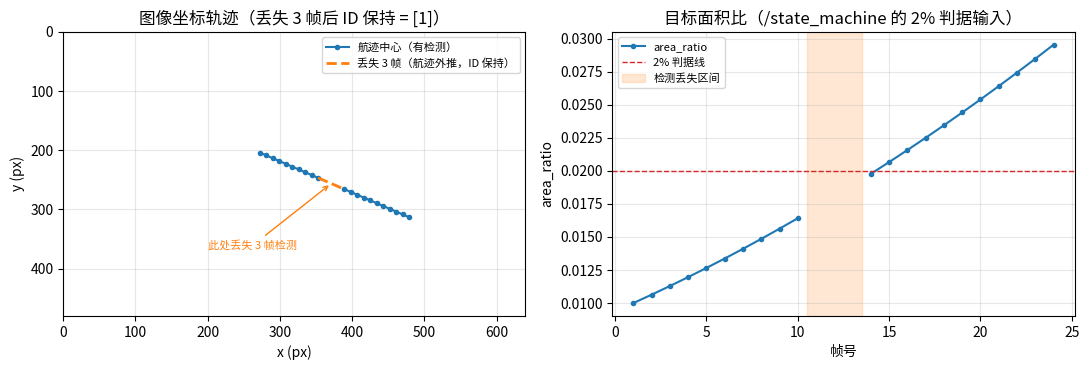

出现过的 ID: [1] → 丢失后 ID 保持不变


In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

try:
    import visual_tracker as vt
    import visual_tracker_node as vtn
    from uav_tracking.msg import Detections as TrackerDetectionsMsg
    from uav_tracking.msg import DetectedTarget as TrackerDetectedTargetMsg

    COLOR_TRACK = "#1f77b4"      # 航迹（与 visual_tracker.ipynb §7 一致）
    COLOR_LOSS = "#ff7f0e"       # 丢失 / 外推段
    COLOR_JUDGE = "#d62728"      # 判据线

    vt.reset()
    vt.setup(frame_size=(640, 480))

    frames, cx, cy, ids, areas = [], [], [], [], []
    LOST = range(10, 13)          # 连续丢 3 帧检测（远小于 track_buffer，ID 应保持）
    for i in range(24):
        m = TrackerDetectionsMsg()
        if i not in LOST:
            t = TrackerDetectedTargetMsg()
            t.class_id = 0
            t.confidence = 0.9
            t.bbox = [240.0 + i * 8.0, 180.0 + i * 4.0,
                      64.0 + i * 2.0, 48.0 + i * 1.5]
            m.targets.append(t)
        tracks = vt.track(vtn.detections_from_msg(m))
        out = vtn.visual_tracks_to_msg(tracks)
        frames.append(i + 1)
        if out.tracks:
            b = out.tracks[0].bbox
            cx.append(b[0] + b[2] / 2.0)
            cy.append(b[1] + b[3] / 2.0)
            ids.append(int(out.tracks[0].id))
            areas.append(float(out.tracks[0].area_ratio))
        else:
            cx.append(np.nan); cy.append(np.nan); ids.append(None); areas.append(np.nan)

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

    # 左：图像坐标轨迹。注意 x 轴单位是像素，丢失区间不能画 axvspan，
    #     改画成「丢失前后两点之间的外推虚线」
    axes[0].plot(cx, cy, "-o", color=COLOR_TRACK, markersize=3, label="航迹中心（有检测）")
    _nan = [i for i, a in enumerate(areas) if np.isnan(a)]
    if _nan:
        i0, i1 = _nan[0] - 1, _nan[-1] + 1
        axes[0].plot([cx[i0], cx[i1]], [cy[i0], cy[i1]], "--", color=COLOR_LOSS,
                     linewidth=2, label="丢失 %d 帧（航迹外推，ID 保持）" % len(_nan))
        _mid = ((cx[i0] + cx[i1]) / 2.0, (cy[i0] + cy[i1]) / 2.0)
        axes[0].annotate("此处丢失 %d 帧检测" % len(_nan), xy=_mid,
                         xytext=(_mid[0] - 170, _mid[1] + 110), color=COLOR_LOSS, fontsize=8,
                         arrowprops=dict(arrowstyle="->", color=COLOR_LOSS))
    axes[0].set_xlim(0, 640); axes[0].set_ylim(480, 0)     # 图像坐标：y 向下
    axes[0].set_xlabel("x (px)"); axes[0].set_ylabel("y (px)")
    axes[0].set_title("图像坐标轨迹（丢失 %d 帧后 ID 保持 = %s）"
                      % (len([1 for v in ids if v is None]),
                         sorted({i for i in ids if i is not None})))
    axes[0].grid(alpha=0.3); axes[0].legend(loc="upper right", fontsize=8)

    # 右：area_ratio（x 轴是帧号，axvspan 在这儿才对）
    axes[1].plot(frames, areas, "-o", color=COLOR_TRACK, markersize=3, label="area_ratio")
    axes[1].axvspan(10.5, 13.5, color=COLOR_LOSS, alpha=0.18, label="检测丢失区间")
    axes[1].axhline(0.02, color=COLOR_JUDGE, ls="--", lw=1, label="2% 判据线")
    axes[1].set_xlabel("帧号"); axes[1].set_ylabel("area_ratio")
    axes[1].set_title("目标面积比（/state_machine 的 2% 判据输入）")
    axes[1].grid(alpha=0.3); axes[1].legend(loc="upper left", fontsize=8)

    plt.tight_layout(); plt.show()

    alive = sorted({i for i in ids if i is not None})
    print("出现过的 ID:", alive, "→", "丢失后 ID 保持不变" if len(alive) == 1 else "ID 发生变化")
    vt.reset()
except ImportError as exc:
    print("[跳过] 需先 source ROS 并 catkin_make：", exc)


## 5. 端到端 E2E

```bash
bash test/visual_tracker/e2e_test/run_e2e.sh
```

- **阶段 A（有目标）**：断言航迹产出、`area_ratio` 与 `bbox/(画面面积)` 一致、
  **ID 跨帧稳定**；
- **阶段 B（无目标）**：断言话题仍在流且 `tracks` 恒为空（「空也发」契约）。